from IPython.display import display
# Clustering

## 1. Problem Statement
The goal of this clustering track is to discover inherent groupings in the Seismic Bumps dataset without relying on the ground-truth class labels. We aim to identify patterns in the seismic and seismoacoustic features that may group similar instances together.

## 2. Dataset Description
This dataset contains seismic bump data. Numerical features record various energy and pulse measurements, while categorical features record qualitative assessments. The ground-truth `class` indicates whether a hazardous bump occurred (1) or not (0).

## 3. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.io import arff

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA
from IPython.display import display

## 4. Load Dataset
The dataset is stored locally in the `data/` directory. We will use a portable relative path to locate and load the ARFF file.

In [2]:
data_dir = Path("../data")
arff_files = list(data_dir.glob("*.arff"))
print("Found ARFF files:", [f.name for f in arff_files])

# Select the seismic-bumps.arff file
target_file = next(f for f in arff_files if f.name == "seismic-bumps.arff")
print(f"Loading {target_file.name}...")

data, meta = arff.loadarff(target_file)
df = pd.DataFrame(data)

# Decode byte strings in categorical columns
for col in df.columns:
    if df[col].dtype == object:
        df[col] = df[col].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)

print("Dataset shape:", df.shape)
df.head()

Found ARFF files: ['seismic-bumps.arff']
Loading seismic-bumps.arff...
Dataset shape: (2584, 19)


,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,ghazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
0,a,a,N,15180.0,48.0,-72.0,-72.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,a,a,N,14720.0,33.0,-70.0,-79.0,a,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2000.0,2000.0,0
2,a,a,N,8050.0,30.0,-81.0,-78.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,a,a,N,28820.0,171.0,-23.0,40.0,a,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3000.0,3000.0,0
4,a,a,N,12640.0,57.0,-63.0,-52.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


## 5. Data Audit

In [3]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nCategorical Feature Unique Values:")
for col in df.select_dtypes(include=['object']).columns:
    print(f"{col}: {df[col].unique()}")

print("\nDescriptive Statistics:")
display(df.describe(include="all"))

Data Types:
seismic            object
seismoacoustic     object
shift              object
genergy           float64
gpuls             float64
gdenergy          float64
gdpuls            float64
ghazard            object
nbumps            float64
nbumps2           float64
nbumps3           float64
nbumps4           float64
nbumps5           float64
nbumps6           float64
nbumps7           float64
nbumps89          float64
energy            float64
maxenergy         float64
class              object
dtype: object

Missing Values: 0
Duplicate Rows: 6

Categorical Feature Unique Values:
seismic: ['a' 'b']
seismoacoustic: ['a' 'b' 'c']
shift: ['N' 'W']
ghazard: ['a' 'b' 'c']
class: ['0' '1']

Descriptive Statistics:


,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,ghazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
count,2584,2584,2584,2.584000e+03,2584.000000,2584.000000,2584.000000,2584,2584.000000,2584.000000,2584.000000,2584.000000,2584.000000,2584.0,2584.0,2584.0,2584.000000,2584.000000,2584
unique,2,3,2,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,a,a,W,NaN,NaN,NaN,NaN,a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
freq,1682,1580,1663,NaN,NaN,NaN,NaN,2342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2414
mean,NaN,NaN,NaN,9.024252e+04,538.579334,12.375774,4.508901,NaN,0.859520,0.393576,0.392802,0.067724,0.004644,0.0,0.0,0.0,4975.270898,4278.850619,NaN
std,NaN,NaN,NaN,2.292005e+05,562.652536,80.319051,63.166556,NaN,1.364616,0.783772,0.769710,0.279059,0.068001,0.0,0.0,0.0,20450.833222,19357.454882,NaN
min,NaN,NaN,NaN,1.000000e+02,2.000000,-96.000000,-96.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,NaN
25%,NaN,NaN,NaN,1.166000e+04,190.000000,-37.000000,-36.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,NaN
50%,NaN,NaN,NaN,2.548500e+04,379.000000,-6.000000,-6.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,NaN
75%,NaN,NaN,NaN,5.283250e+04,669.000000,38.000000,30.250000,NaN,1.000000,1.000000,1.000000,0.000000,0.000000,0.0,0.0,0.0,2600.000000,2000.000000,NaN


## 6. Exploratory Data Analysis
The dataset has 2584 rows. There are no missing values, but 6 duplicate rows exist. We will keep them for this unsupervised learning exercise as they may represent genuinely identical concurrent events. The descriptive statistics confirm distinct scales among numerical features (e.g., `genergy` in tens of thousands vs `nbumps` mostly 0-5).

## 7. Data Preprocessing
First, we will identify numerical and categorical features. The ground-truth `class` attribute must be strictly excluded from clustering.

In [4]:
# Identify categorical and numerical features
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df.select_dtypes(exclude=[np.number]).columns.tolist()

# The ground-truth class is categorical but must be excluded from features
if "class" in categorical_features:
    categorical_features.remove("class")

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numeric Features: ['genergy', 'gpuls', 'gdenergy', 'gdpuls', 'nbumps', 'nbumps2', 'nbumps3', 'nbumps4', 'nbumps5', 'nbumps6', 'nbumps7', 'nbumps89', 'energy', 'maxenergy']
Categorical Features: ['seismic', 'seismoacoustic', 'shift', 'ghazard']


## 8. Separate Ground-Truth Class
Since K-Means is an unsupervised algorithm, the ground-truth `class` is excluded from model fitting. It may be used only after clustering for interpretation or validation.

In [5]:
y_true = df["class"]
X = df.drop(columns=["class"])

print("Features shape (X):", X.shape)
print("Ground truth shape (y_true):", y_true.shape)

Features shape (X): (2584, 18)
Ground truth shape (y_true): (2584,)


## 9. Encode Categorical Features
## 10. Feature Scaling
K-Means assigns observations to clusters based on distance from cluster centroids. If numerical features have very different scales, large-scale features can dominate the distance calculation. Therefore, we use `StandardScaler` to standardize numerical features, and `OneHotEncoder` for categorical features.

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)
print("Processed Matrix Shape:", X_processed.shape)

Processed Matrix Shape: (2584, 24)


## 11. K-Means Clustering

### 11.1 K-Means Intuition
K-Means groups observations into K clusters based on similarity. Basic steps:
1. Choose K (number of clusters).
2. Initialize K centroids randomly.
3. Assign each observation to the nearest centroid.
4. Recalculate centroids based on current assignments.
5. Repeat assignment and centroid updates.
6. Stop when convergence occurs or the iteration limit is reached.

Key metrics include **inertia** (sum of squared distances of samples to their closest cluster center).

### 11.2 Choosing Number of Clusters
### 11.3 Elbow Method
### 11.4 Silhouette Analysis
We will evaluate candidate values of $K \in [2, 10]$ using the Elbow Method (inertia) and Silhouette Score.

In [7]:
k_values = range(2, 11)
inertia_values = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_processed)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_processed, labels))

results_df = pd.DataFrame({
    "k": k_values,
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_scores
})

display(results_df)

,k,Inertia,Silhouette Score
0,2,26327.873082,0.470200
1,3,20860.512721,0.437213
2,4,18358.299044,0.252613
3,5,15929.675266,0.264497
4,6,13890.342749,0.282166
5,7,12805.784996,0.195494
6,8,12073.287481,0.199607
7,9,11506.570358,0.185959
8,10,11094.253428,0.186616


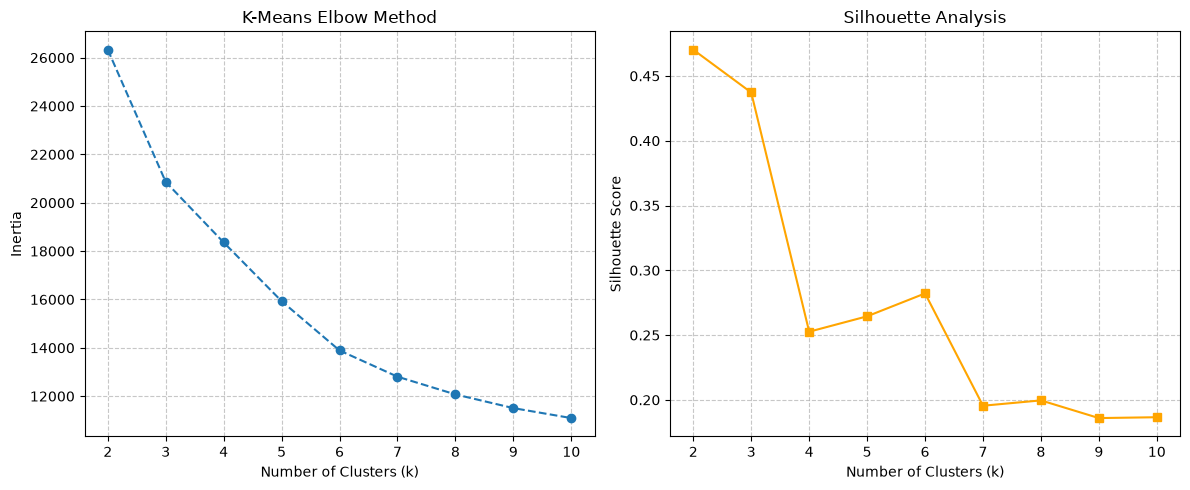

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia_values, marker='o', linestyle='--')
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.grid(True, linestyle="--", alpha=0.7)

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker='s', linestyle='-', color='orange')
plt.title("Silhouette Analysis")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

The elbow is not sharp, with a visible bend around k = 2-3. The silhouette analysis peaks at k = 2 (highest score: ~0.47), with k = 3 close behind (~0.44). Therefore, **k = 2** is selected for the K-Means model.

### 11.5 Final K-Means Model

In [9]:
chosen_k = 2

kmeans_final = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_processed)

df_clustered = df.copy()
df_clustered["cluster"] = cluster_labels
print("Cluster assignment complete.")

Cluster assignment complete.


### 11.6 Cluster Evaluation

In [10]:
silhouette_final = silhouette_score(X_processed, cluster_labels)
davies_bouldin_final = davies_bouldin_score(X_processed, cluster_labels)
calinski_harabasz_final = calinski_harabasz_score(X_processed, cluster_labels)

kmeans_eval_df = pd.DataFrame({
    "Algorithm": ["K-Means"],
    "K": [chosen_k],
    "Silhouette": [silhouette_final],
    "Davies-Bouldin": [davies_bouldin_final],
    "Calinski-Harabasz": [calinski_harabasz_final]
})

display(kmeans_eval_df.round(4))

,Algorithm,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,0.4702,1.6817,604.39


### 11.7 PCA Visualization
PCA is used only to reduce the high-dimensional processed feature space to two dimensions for visualization. PCA is not used to create the cluster labels.

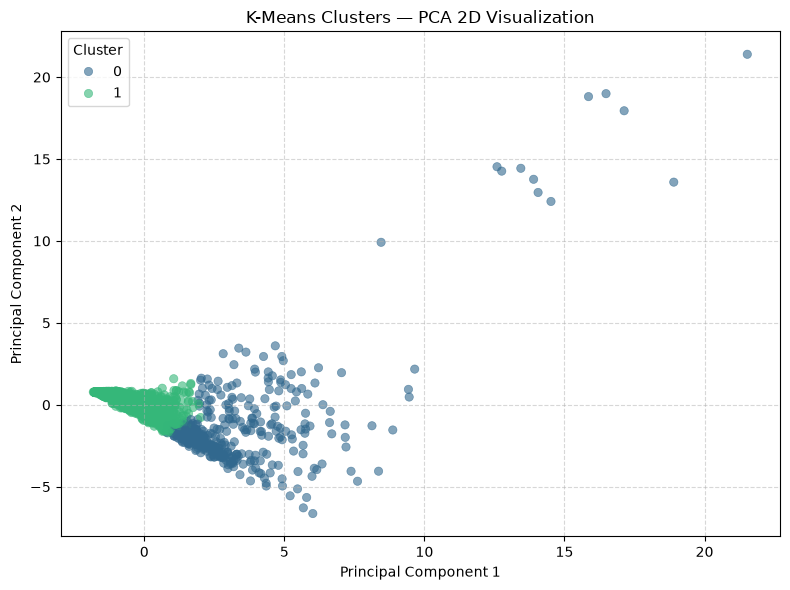

Explained variance ratio: [0.29065532 0.1766348 ]
Total explained variance: 0.4672901158891545


In [11]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=cluster_labels, 
    palette="viridis", 
    alpha=0.6,
    edgecolor=None
)
plt.title("K-Means Clusters — PCA 2D Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

### 11.8 Optional Ground-Truth Interpretation
Cluster Size Analysis and Post-clustering comparison with ground-truth class — NOT used during model fitting.

In [12]:
print("Cluster Sizes:")
print(df_clustered["cluster"].value_counts().sort_index())

print("\nPost-clustering comparison with ground-truth class:")
crosstab_res = pd.crosstab(
    df_clustered["cluster"],
    y_true,
    rownames=["Cluster"],
    colnames=["Ground-Truth Class"]
)
display(crosstab_res)

# Data Integrity Checks
assert df.shape[0] == df_clustered.shape[0]
assert "class" not in X.columns
assert len(np.unique(cluster_labels)) == chosen_k
assert not np.isnan(X_processed).any()
print("\nData integrity checks passed.")

Cluster Sizes:
cluster
0     403
1    2181
Name: count, dtype: int64

Post-clustering comparison with ground-truth class:


Ground-Truth Class,0,1
Cluster,,
0,320,83
1,2094,87



Data integrity checks passed.


## 12. Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is a bottom-up clustering method.
Initially, every observation is treated as its own individual cluster. Then:
1. Find the two closest clusters.
2. Merge them into a new, larger cluster.
3. Recalculate distances between the new cluster and all other clusters.
4. Merge the next closest clusters.
5. Continue this process iteratively until all observations are merged into a single overarching hierarchy.

The resulting hierarchy can be visualized using a **dendrogram**.

Important terms:
- **Cluster**: A group of similar observations.
- **Hierarchy**: The tree-like structure of nested merges.
- **Linkage**: The criterion used to determine the distance between sets of observations.
- **Dendrogram**: A diagram that shows the hierarchical relationship between objects.
- **Merge**: Combining two clusters into one.

### 12.1 Linkage Strategies
The university guidelines require comparing linkage strategies. We will evaluate:
- **Ward**: Attempts to minimize the increase in within-cluster variance when merging clusters. It is intended for Euclidean distance.
- **Complete**: Uses the maximum distance between points in two clusters to dictate merging.
- **Average**: Uses the average distance between all points in two clusters.

### 12.2 Dendrogram Visualization
To visually inspect the hierarchy and determine an appropriate number of clusters, we generate a dendrogram using Ward linkage. To maintain readability with 2,584 observations, the dendrogram is truncated to show the top levels of the hierarchy.

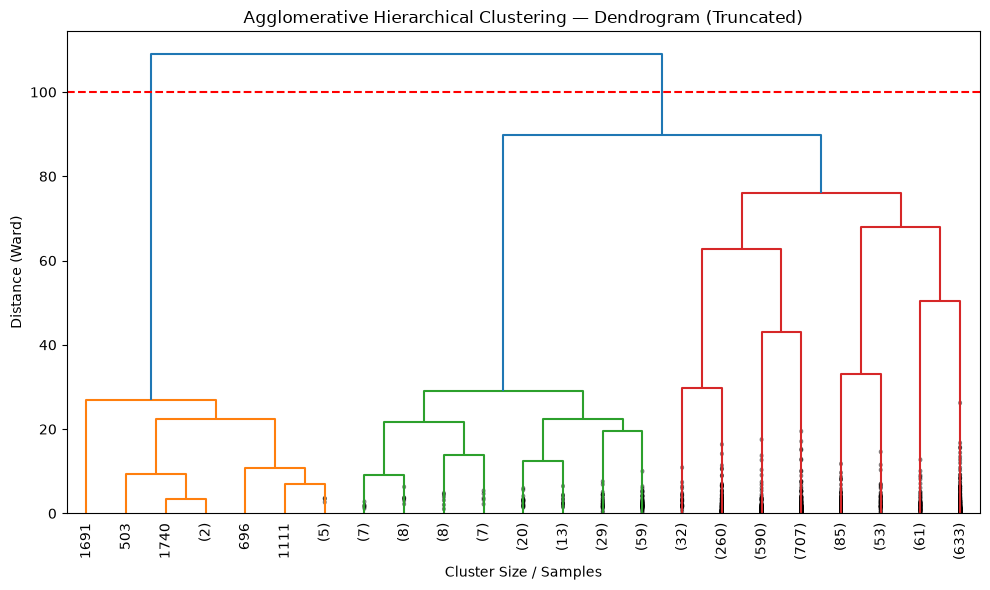

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Compute the linkage matrix using Ward
Z = linkage(X_processed, method='ward')

plt.figure(figsize=(10, 6))
dendrogram(
    Z,
    truncate_mode='level', 
    p=4,  # show only the last 4 levels of merges
    show_leaf_counts=True,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title("Agglomerative Hierarchical Clustering — Dendrogram (Truncated)")
plt.xlabel("Cluster Size / Samples")
plt.ylabel("Distance (Ward)")
plt.axhline(y=100, color='r', linestyle='--') # Example cut line
plt.tight_layout()
plt.show()

### 12.3 Choosing Number of Clusters and Linkage Method
Based on the dendrogram and the previous K-Means analysis, we will evaluate $K \in [2, 5]$ across the three main linkage criteria (Ward, Complete, Average). The evaluation uses unsupervised metrics: Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. Ground-truth `class` is strictly excluded.

In [14]:
from sklearn.cluster import AgglomerativeClustering

agg_results = []
k_candidates = range(2, 6)
linkages = ["ward", "complete", "average"]

for link in linkages:
    for k in k_candidates:
        model = AgglomerativeClustering(n_clusters=k, linkage=link)
        labels = model.fit_predict(X_processed)
        
        sil = silhouette_score(X_processed, labels)
        db = davies_bouldin_score(X_processed, labels)
        ch = calinski_harabasz_score(X_processed, labels)
        
        agg_results.append({
            "Linkage": link.capitalize(),
            "K": k,
            "Silhouette": sil,
            "Davies-Bouldin": db,
            "Calinski-Harabasz": ch
        })

agg_results_df = pd.DataFrame(agg_results)
display(agg_results_df.round(4).sort_values(by=["Silhouette"], ascending=False))

,Linkage,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Ward,2,0.8320,0.4258,577.2142
4,Complete,2,0.8320,0.4258,577.2142
8,Average,2,0.8320,0.4258,577.2142
9,Average,3,0.8280,0.3396,310.3890
5,Complete,3,0.8280,0.3396,310.3890
6,Complete,4,0.8059,0.4873,217.1661
10,Average,4,0.6715,0.3120,212.5925
11,Average,5,0.6710,0.4357,167.2038
1,Ward,3,0.4776,0.9424,570.4990
7,Complete,5,0.4718,0.7933,298.6041


From the evaluation above, Ward, Complete and Average linkage give identical results at K=2 (Silhouette 0.8320, Davies-Bouldin 0.4258, Calinski-Harabasz 577.21). This high silhouette must be read with care: the K=2 split isolates only **12 outlying observations** from the other 2,572, so the score reflects a tiny, very distant outlier group rather than well-balanced structure. Ward at K=3 gives a lower silhouette (0.4776) but a much higher Calinski-Harabasz index (570.50) relative to complete/average at the same K, i.e. more compact clusters.

We keep **Ward** linkage with **K=2** for the final Agglomerative model, to stay comparable with K-Means (K=2) on the same preprocessed matrix, and we flag the outlier-dominated split as a limitation in the comparison below.

### 12.4 Final Agglomerative Model

In [15]:
chosen_agg_k = 2
chosen_linkage = "ward"

agg_final = AgglomerativeClustering(n_clusters=chosen_agg_k, linkage=chosen_linkage)
agg_labels = agg_final.fit_predict(X_processed)

# Assign labels to dataset copy for interpretation
df_clustered_agg = df.copy()
df_clustered_agg["cluster"] = agg_labels
print("Agglomerative cluster assignment complete.")

Agglomerative cluster assignment complete.


### 12.5 Required Final Metrics

In [16]:
agg_sil = silhouette_score(X_processed, agg_labels)
agg_db = davies_bouldin_score(X_processed, agg_labels)
agg_ch = calinski_harabasz_score(X_processed, agg_labels)

agg_eval_df = pd.DataFrame({
    "Algorithm": ["Agglomerative"],
    "K": [chosen_agg_k],
    "Linkage": [chosen_linkage.capitalize()],
    "Silhouette": [agg_sil],
    "Davies-Bouldin": [agg_db],
    "Calinski-Harabasz": [agg_ch]
})

print("Final Agglomerative Metrics:")
display(agg_eval_df.round(4))

Final Agglomerative Metrics:


,Algorithm,K,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Agglomerative,2,Ward,0.832,0.4258,577.2142


### 12.6 PCA Visualization
We reuse the PCA transformation (`X_pca`) already fitted during the K-Means phase to visualize the Agglomerative clusters.

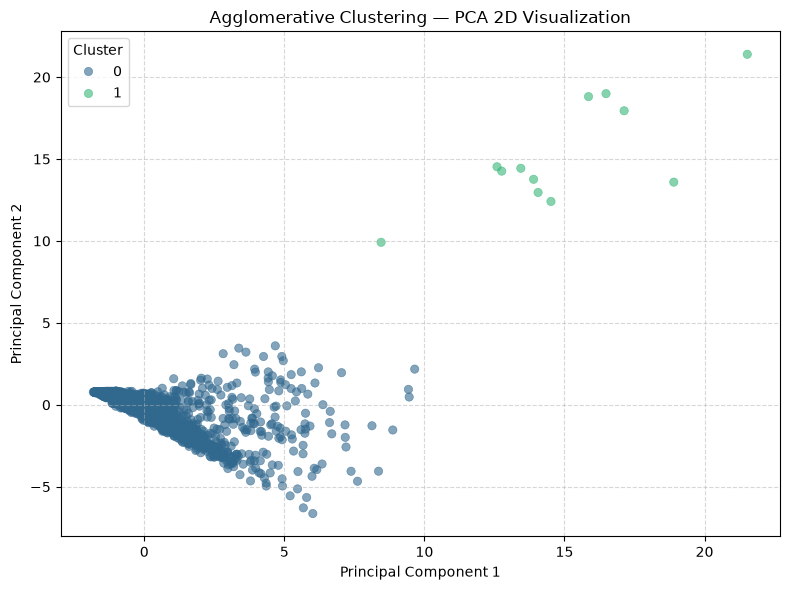

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=agg_labels, 
    palette="viridis", 
    alpha=0.6,
    edgecolor=None
)
plt.title("Agglomerative Clustering — PCA 2D Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 12.7 Cluster Size Analysis and Optional Interpretation
The ground-truth `class` is evaluated against the final cluster labels purely for post-clustering interpretation.

In [18]:
print("Agglomerative Cluster Sizes:")
print(pd.Series(agg_labels).value_counts().sort_index())

print("\nPost-clustering comparison with ground-truth class — NOT used during model fitting:")
crosstab_agg = pd.crosstab(
    df_clustered_agg["cluster"],
    y_true,
    rownames=["Cluster (Agglomerative)"],
    colnames=["Ground-Truth Class"]
)
display(crosstab_agg)

Agglomerative Cluster Sizes:
0    2572
1      12
Name: count, dtype: int64

Post-clustering comparison with ground-truth class — NOT used during model fitting:


Ground-Truth Class,0,1
Cluster (Agglomerative),,
0,2403,169
1,11,1


## 13. K-Means vs Agglomerative Comparison
A preliminary comparison of the two requested clustering algorithms on the same dataset and preprocessed feature matrix.

In [19]:
# Re-create K-Means evaluation row to match formatting
kmeans_comparison_row = {
    "Algorithm": "K-Means",
    "K": chosen_k,
    "Linkage": "—",
    "Silhouette": silhouette_final,
    "Davies-Bouldin": davies_bouldin_final,
    "Calinski-Harabasz": calinski_harabasz_final
}

agg_comparison_row = {
    "Algorithm": "Agglomerative",
    "K": chosen_agg_k,
    "Linkage": chosen_linkage.capitalize(),
    "Silhouette": agg_sil,
    "Davies-Bouldin": agg_db,
    "Calinski-Harabasz": agg_ch
}

clustering_comparison_df = pd.DataFrame([kmeans_comparison_row, agg_comparison_row])
display(clustering_comparison_df.round(4))

,Algorithm,K,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,—,0.4702,1.6817,604.3900
1,Agglomerative,2,Ward,0.8320,0.4258,577.2142


### 13.1 Interpretation of the Comparison

| Aspect | K-Means (K=2) | Agglomerative, Ward (K=2) |
|--------|---------------|---------------------------|
| Cluster sizes | 403 / 2,181 (reasonably balanced) | 2,572 / 12 (outlier-dominated) |
| Silhouette (higher is better) | 0.4702 | 0.8320 (inflated by the 12-point outlier cluster) |
| Davies-Bouldin (lower is better) | 1.6817 | 0.4258 |
| Calinski-Harabasz (higher is better) | 604.39 | 577.21 |

**Trade-off:** Agglomerative scores better on Silhouette and Davies-Bouldin, but only because it separates a handful of extreme events. K-Means gives the more informative partition (about 16% of observations in the smaller cluster) and the higher Calinski-Harabasz index, so it is the more useful segmentation for this dataset. Neither clustering aligns strongly with the ground-truth hazard `class` (see the cross-tabulations above), which is expected as the labels were not used for fitting and the classes are highly imbalanced.

## 14. t-SNE Visualization

### 14.1 Why t-SNE?
t-SNE (t-distributed Stochastic Neighbor Embedding) is a nonlinear dimensionality-reduction technique primarily used to visualize high-dimensional data in 2D or 3D.
Unlike PCA, which preserves global variance, t-SNE focuses on preserving local neighbourhood relationships, grouping similar instances together.

For this project, t-SNE is being used ONLY for visualization. The clustering models have already been evaluated using `X_processed`.

### 14.2 t-SNE Configuration
We apply t-SNE with the following key parameters:
- `n_components=2`: Reduces the data to two dimensions for visual plotting.
- `perplexity=30`: Controls the approximate number of neighbouring points considered when constructing the local similarity relationships. It influences the balance between local and broader structure.
- `random_state=42`: Makes the embedding reproducible.
- `init="pca"`: Uses PCA-based initialization rather than random initialization. This provides a more stable starting point.
- `learning_rate="auto"`: Allows scikit-learn to choose a suitable learning rate automatically.

**Note**: The ground-truth `class` was absolutely NOT used to calculate the t-SNE embedding. Cluster labels are only used to color the visualization after the embedding is generated.

### 14.3 t-SNE 2D Embedding

In [20]:
from sklearn.manifold import TSNE

# Fit t-SNE using the fully processed feature matrix.
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    learning_rate="auto",
    init="pca"
)

X_tsne = tsne.fit_transform(X_processed)

print("t-SNE embedding shape:", X_tsne.shape)

# Data Integrity Check
assert X_tsne.shape[0] == X_processed.shape[0]
assert X_tsne.shape[1] == 2
assert len(cluster_labels) == len(X_tsne)

t-SNE embedding shape: (2584, 2)


### 14.4 K-Means t-SNE Visualization
We color the t-SNE embedding using the labels generated by our selected K-Means model.

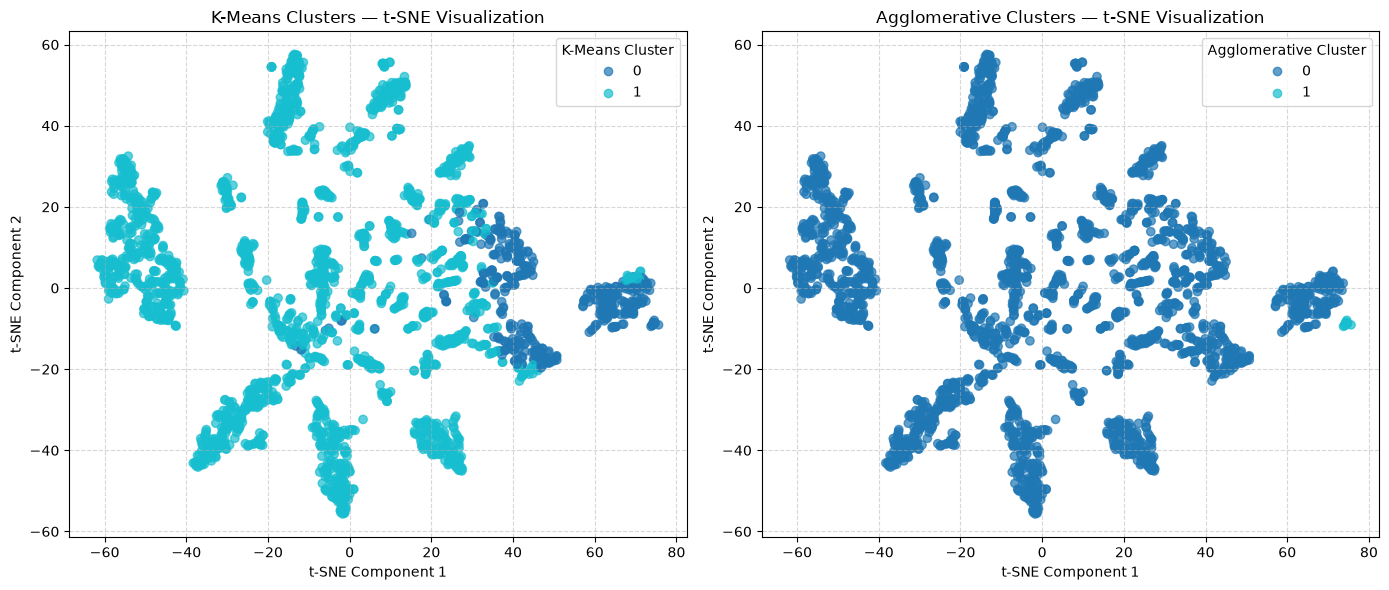

In [21]:
plt.figure(figsize=(14, 6))

# Plot K-Means clusters
plt.subplot(1, 2, 1)
scatter_kmeans = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=cluster_labels,
    cmap="tab10",
    alpha=0.7
)
plt.title("K-Means Clusters — t-SNE Visualization")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(*scatter_kmeans.legend_elements(), title="K-Means Cluster")
plt.grid(True, linestyle="--", alpha=0.5)

# Plot Agglomerative clusters
plt.subplot(1, 2, 2)
scatter_agg = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=agg_labels,
    cmap="tab10",
    alpha=0.7
)
plt.title("Agglomerative Clusters — t-SNE Visualization")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(*scatter_agg.legend_elements(), title="Agglomerative Cluster")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()